# Parse IMDb description pages

Parse the saved HTML files in `descriptions/` into one row per IMDb title and write `imdb_descriptions.csv`. The parser reads title, director, writers, stars, and genres from IMDb's embedded page data, then creates a separate CSV column for each labeled field in the Details and Box office sections. The archived snapshot timestamp is intentionally omitted.

Files that are browser error pages are kept as rows with their IMDb ID, source path, and `unavailable_page` parse status; fields that could not be read remain blank.

In [ ]:
import csv
import json
import re
from pathlib import Path

from bs4 import BeautifulSoup


HTML_DIR = Path("descriptions")
OUTPUT_CSV = Path("imdb_descriptions.csv")
BASE_FIELDS = [
    "imdb_id",
    "title",
    "director",
    "writers",
    "stars",
    "genres",
    "parse_status",
    "source_file",
]


def clean_text(value):
    return " ".join(str(value or "").split())


def json_ld_objects(soup):
    objects = []
    for script in soup.select('script[type="application/ld+json"]'):
        try:
            objects.append(json.loads(script.string or script.get_text()))
        except json.JSONDecodeError:
            continue
    return objects


def find_movie_jsonld(objects):
    pending = list(objects)
    while pending:
        item = pending.pop()
        if isinstance(item, list):
            pending.extend(item)
        elif isinstance(item, dict):
            item_type = item.get("@type", [])
            if isinstance(item_type, str):
                item_type = [item_type]
            if any("Movie" in str(value) for value in item_type):
                return item
            pending.extend(item.values())
    return {}


def text_values(values):
    if values is None:
        return []
    if not isinstance(values, list):
        values = [values]
    result = []
    for value in values:
        if isinstance(value, dict):
            value = value.get("name") or value.get("text") or value.get("nameText", {}).get("text", "")
        if isinstance(value, str) and clean_text(value):
            result.append(clean_text(value))
    return result


def principal_credits(page_data, movie_jsonld):
    credits = {"director": [], "writers": [], "stars": []}
    above_fold = page_data.get("aboveTheFoldData", {})
    groupings = above_fold.get("principalCreditsV2", [])
    label_map = {"director": "director", "writers": "writers", "stars": "stars"}
    for grouping in groupings:
        grouping_name = clean_text(grouping.get("grouping", {}).get("text", "")).casefold()
        field = label_map.get(grouping_name)
        if not field:
            continue
        for credit in grouping.get("credits", []):
            name = clean_text(credit.get("name", {}).get("nameText", {}).get("text", ""))
            if name:
                credits[field].append(name)

    for field, jsonld_key in (("director", "director"), ("writers", "creator"), ("stars", "actor")):
        if not credits[field]:
            credits[field] = text_values(movie_jsonld.get(jsonld_key))
    return credits


def slugify(value):
    return re.sub(r"[^a-z0-9]+", "_", clean_text(value).casefold()).strip("_")


SECTION_LABEL_ALIASES = {
    "details": {
        "country_of_origin": "country_of_origin",
        "countries_of_origin": "country_of_origin",
        "language": "languages",
        "languages": "languages",
        "production_company": "production_companies",
        "production_companies": "production_companies",
    },
}


def section_value(element):
    list_items = element.select("ul > li")
    values = [clean_text(item.get_text(" ", strip=True)) for item in list_items]
    values = [value for value in values if value]
    if values:
        return "; ".join(dict.fromkeys(values))
    return clean_text(element.get_text(" ", strip=True))


def section_fields(soup, section_name, header_testid, item_prefix):
    header = soup.select_one(f'[data-testid="{header_testid}"]')
    section = header.find_parent("section") if header else None
    if section is None:
        return {}

    aliases = SECTION_LABEL_ALIASES.get(section_name, {})
    result = {}
    for item in section.select(f'li[data-testid^="{item_prefix}"]'):
        children = item.find_all(recursive=False)
        if len(children) < 2:
            continue
        label = clean_text(children[0].get_text(" ", strip=True))
        value = section_value(children[1])
        if not label or not value or label.casefold().startswith("see more"):
            continue
        label_key = slugify(label)
        column = f"{section_name}_{aliases.get(label_key, label_key)}"
        if column in result and value not in result[column].split("; "):
            result[column] = f"{result[column]}; {value}"
        else:
            result[column] = value
    return result


def parse_page(source):
    html = source.read_text(encoding="utf-8", errors="replace")
    soup = BeautifulSoup(html, "html.parser")
    imdb_match = re.search(r"tt\d+", source.name)
    imdb_id = imdb_match.group(0) if imdb_match else ""

    next_data = soup.select_one("script#__NEXT_DATA__")
    page_data = {}
    if next_data:
        try:
            page_data = json.loads(next_data.string or next_data.get_text()).get("props", {}).get("pageProps", {})
        except json.JSONDecodeError:
            page_data = {}
    if not imdb_id:
        imdb_id = clean_text(page_data.get("tconst", ""))

    movie_jsonld = find_movie_jsonld(json_ld_objects(soup))
    above_fold = page_data.get("aboveTheFoldData", {})
    title = clean_text(above_fold.get("titleText", {}).get("text", ""))
    title = title or clean_text(movie_jsonld.get("name", ""))
    if not title and soup.title:
        title = re.sub(r"\s+-\s+IMDb\s*$", "", clean_text(soup.title.get_text(" ", strip=True)))
        if title.casefold() == "web.archive.org":
            title = ""

    genre_data = above_fold.get("genres", {}).get("genres", [])
    genres = text_values(genre_data) or text_values(movie_jsonld.get("genre"))
    credits = principal_credits(page_data, movie_jsonld)
    row = {
        "imdb_id": imdb_id,
        "title": title,
        "director": "; ".join(credits["director"]),
        "writers": "; ".join(credits["writers"]),
        "stars": "; ".join(credits["stars"]),
        "genres": "; ".join(genres),
        "parse_status": "ok" if page_data or movie_jsonld else "unavailable_page",
        "source_file": str(source),
    }
    row.update(section_fields(soup, "details", "title-details-header", "title-details-"))
    row.update(section_fields(soup, "box_office", "title-boxoffice-header", "title-boxoffice-"))
    return row


html_files = sorted(HTML_DIR.glob("*.html"))
if not html_files:
    raise FileNotFoundError(f"No HTML files found in {HTML_DIR}")

rows = [parse_page(path) for path in html_files]
movie_ids = [row["imdb_id"] for row in rows]
if any(not imdb_id for imdb_id in movie_ids):
    raise ValueError("At least one description filename did not contain an IMDb ID")
if len(movie_ids) != len(set(movie_ids)):
    raise ValueError("Description pages contain duplicate IMDb IDs; refusing to write multiple rows per movie")

section_fields_found = sorted({
    key
    for row in rows
    for key in row
    if key.startswith("details_") or key.startswith("box_office_")
})
fieldnames = BASE_FIELDS[:6] + section_fields_found + BASE_FIELDS[6:]
with OUTPUT_CSV.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

unavailable = [row for row in rows if row["parse_status"] != "ok"]
print(f"Wrote {len(rows)} movies to {OUTPUT_CSV}")
print(f"Fields: {', '.join(fieldnames)}")
print(f"Unavailable pages: {len(unavailable)}")
for row in unavailable:
    print(f"  {row['imdb_id']}: {row['source_file']}")

____Head____


,imdb_id,title,director,writers,stars,genres,box_office_budget,box_office_gross_us_canada,box_office_gross_worldwide,box_office_opening_weekend_us_canada,details_also_known_as,details_countries_of_origin,details_country_of_origin,details_filming_locations,details_language,details_languages,details_production_companies,details_production_company,details_release_date,parse_status,source_file
0,tt0871510,Chak De! India,Shimit Amin,Jaideep Sahni,Shah Rukh Khan; Vidya Malvade; Sagarika Ghatge,Drama; Family; Sport,NaN,"$1,120,404","$21,505,244","$351,887 Aug 12, 2007",Let's Go! India,India United States United Kingdom Australia,NaN,India,NaN,Hindi English,Docklands Studios Melbourne Times Square Allia...,NaN,"August 9, 2007 (Australia)",ok,descriptions/20250214061624_tt0871510.html
1,tt0386064,Taegukgi hwinallimyeo,Kang Je-kyu,Kang Je-kyu; Sang-don Kim; Han Ji-hoon,Jang Dong-gun; Won Bin; Lee Eun-ju,Action; Drama; War,"$12,800,000 (estimated)","$1,111,061","$81,407,286","$260,135 Sep 5, 2004",Hermandad De Guerra,NaN,South Korea,"A-San City, South Korea (Jin-tea's home)",Korean,NaN,Kang Je-Kyu Film Co. Ltd. KD Media KTB Network,NaN,"August 25, 2005 (Netherlands)",ok,descriptions/20260110210846_tt0386064.html
2,tt0074896,The Message,Moustapha Akkad,H.A.L. Craig; Abdel Hamid Gouda El Sahhar; Tew...,Anthony Quinn; Irene Papas; Michael Ansara,Biography; Drama; History; War,"$10,000,000 (estimated)",NaN,NaN,NaN,Mohammad: Messenger of God,Lebanon Libya Kuwait Morocco United Kingdom,NaN,Morocco (Mecca and Medina exteriors),NaN,Arabic English,NaN,Filmco International Productions,"January 31, 1977 (Turkey)",ok,descriptions/20260909172330_tt0074896.html
3,tt0073341,The Man Who Would Be King,John Huston,John Huston; Gladys Hill; Rudyard Kipling,Sean Connery; Michael Caine; Christopher Plummer,Adventure; Drama; War,"$8,000,000 (estimated)",NaN,"$12,796",NaN,L'homme qui voulut être roi,United Kingdom United States,NaN,"Atlas Mountains, Morocco",NaN,English Arabic Urdu,Columbia Pictures Devon/Persky-Bright Allied A...,NaN,"December 19, 1975 (United Kingdom)",ok,descriptions/20260914233951_tt0073341.html
4,tt0118843,"Black Cat, White Cat",Emir Kusturica,Gordan Mihic,Bajram Severdzan; Srdjan 'Zika' Todorovic; Bra...,Comedy; Crime; Romance,NaN,"$351,447","$353,734",NaN,"Chat noir, chat blanc",France Germany Federal Republic of Yugoslavia ...,NaN,"Danube River, Serbia",NaN,Romany Serbian Bulgarian,CiBy 2000 Pandora Filmproduktion Komuna,NaN,"June 1, 1998 (Federal Republic of Yugoslavia)",ok,descriptions/20260920101258_tt0118843.html


____Info____
<class 'pandas.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 21 columns):
 #   Column                                Non-Null Count  Dtype
---  ------                                --------------  -----
 0   imdb_id                               605 non-null    str  
 1   title                                 590 non-null    str  
 2   director                              590 non-null    str  
 3   writers                               590 non-null    str  
 4   stars                                 590 non-null    str  
 5   genres                                590 non-null    str  
 6   box_office_budget                     501 non-null    str  
 7   box_office_gross_us_canada            459 non-null    str  
 8   box_office_gross_worldwide            570 non-null    str  
 9   box_office_opening_weekend_us_canada  414 non-null    str  
 10  details_also_known_as                 589 non-null    str  
 11  details_countries_of_origin           221 n

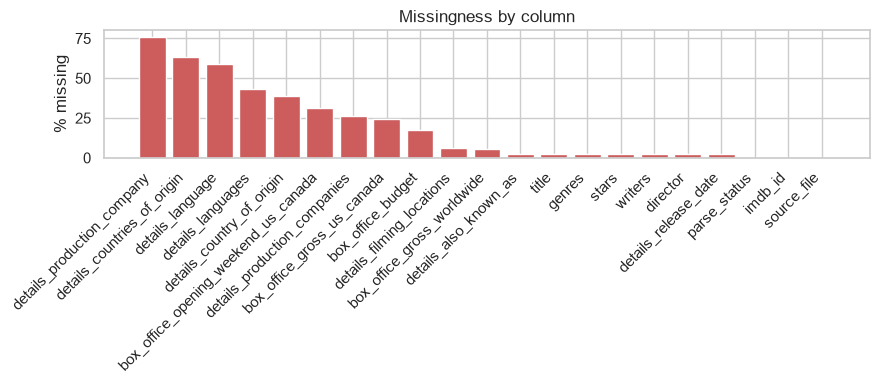

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 30)

df = pd.read_csv("imdb_descriptions.csv")

print("____Head____")
display(df.head())

# print("____Tail____")
# display(df.tail())


print("____Info____")
df_info = df.info()

# display(df_info)

df_copy = df.copy()

# print("========================================")
# print(df_copy.isnull().sum().sort_values(ascending=False))
# print("========================================")
print("\nTotal Missing - ", df_copy.isnull().sum().sum())
print("\nTotal number of values in the data (rows x columns)", len(df_copy)*len(df_copy.columns))
print("\nMissing % - ", df.isnull().sum().sum()/len(df_copy)*len(df_copy.columns*100))
# print("========================================")
# print("\nduplicated - ", df_copy.duplicated().sum())

missing_pct = df_copy.isnull().mean().sort_values(ascending=False) * 100
plt.figure(figsize=(9, 4))
plt.bar(missing_pct.index, missing_pct.values, color="indianred")
plt.ylabel("% missing")
plt.title("Missingness by column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# df_copy['imdb_id'].unique()

# df_export = df_copy[['imdb_id', 'title']].drop_duplicates(subset='imdb_id')

# df_export.to_csv('imdb_ids_with_titles.csv', index=False)